# Live win predictor at 15:00: baseline vs candidate models

**Question.** At the 15:00 mark of a ranked game, which model gives the most trustworthy blue-side win chance,
using only statistics the live game API exposes?

**What this notebook does** (each item maps to a part of the assignment):

| Requirement | Where |
|---|---|
| A baseline and at least two candidate models, same validation method and metrics | Sections 2-4: two baselines, four candidates, one shared cross-validation, five metrics |
| Selection with a justification | Section 5: a selection rule written *before* the results, and the evidence for it |
| Error analysis across groups and conditions | Sections 6-8: rank, patch, game length, conflicting signals, towers, favourite side, confidence, worst misses |
| Runnable evaluation code | The whole notebook; run it top to bottom from the `notebooks/` folder |
| Material for the modeling note | Section 11 prints the key numbers and the limitations in one place |

**To re-run:** `py -m pip install numpy pandas scipy scikit-learn matplotlib jupyter`, put the training CSVs in
`data/training/` (they are not in the git repo; `py prep/prepare.py` rebuilds the live train/test files from
`lol_15min_all.csv`), then run all cells from either the project folder or `notebooks/`. About 2 minutes; every random
choice is seeded, so a re-run reproduces the numbers below exactly.

**Test-set discipline.** The 1,632 held-out matches (`lol_15min_live_test_HOLDOUT.csv`, fingerprinted in
`lol_15min_test_HOLDOUT.sha256`) are **not loaded until Section 10**. Every model choice, every hyperparameter and
every error-analysis plot uses the training split only. The holdout is scored once, for the model chosen in Section 5.

**Metrics.** The overlay shows a *percentage*, so the primary metric is one that judges percentages:

* **Log loss** (primary; lower is better): punishes confident wrong answers hard.
* **Brier score** (lower is better): mean squared error of the percentage.
* **AUC** (higher is better): how well the model ranks winners above losers, whatever the percentages are.
* **Accuracy**: share of games where the side given over 50% won. Easy to explain, but it ignores confidence.
* **ECE**, expected calibration error (lower is better): when the model says 70%, does blue win about 70% of the time?

In [1]:
from collections import Counter
from pathlib import Path
import hashlib
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 100)

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e2dd"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.frameon": False, "legend.fontsize": 8, "lines.linewidth": 2,
})

SEED = 42


def find_root():
    # The project folder, whether Jupyter was started in it or in notebooks/.
    for folder in (Path.cwd(), *Path.cwd().parents):
        if (folder / "data" / "training" / "lol_15min_live_train.csv").exists():
            return folder
    raise FileNotFoundError(
        "data/training/lol_15min_live_train.csv not found. The training CSVs are not in the git repo (see README, 'Data'): "
        "put them in data/training/, or rebuild the live train/test files with `py prep/prepare.py` from lol_15min_all.csv.")


ROOT = find_root()
DATA_DIR = ROOT / "data" / "training"
RANKS = ["IRON", "BRONZE", "SILVER", "GOLD", "PLATINUM", "EMERALD", "DIAMOND", "MASTER_PLUS"]
# The predictors the live API provides (heralds are always 0 at 15:00, so they are left out).
LIVE = ["level_sum_diff", "cs_diff", "kills_diff", "assists_diff", "towers_diff",
        "dragons_diff", "voidgrubs_diff", "blue_first_blood"]

## 1. The data
One row per ranked solo/duo match on NA, captured at 15:00. The target is `blue_win`. Each predictor is a blue-minus-red
difference (positive = blue ahead), except first blood. The train/test split was made in
`lol_15min_live_audit_and_split.ipynb`: 20% of matches held out, stratified by rank and outcome. Only the training
file is read here.

In [2]:
train = pd.read_csv(DATA_DIR / "lol_15min_live_train.csv", dtype={"patch": str})
train["rank_tier"] = pd.Categorical(train.rank_tier, categories=RANKS, ordered=True)
X, y = train[LIVE], train.blue_win.to_numpy()
n = len(train)

import sklearn, scipy
print(f"python-package versions: numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}, "
      f"scipy {scipy.__version__}, matplotlib {plt.matplotlib.__version__}")
print(f"Training matches: {n:,}   blue win rate: {y.mean():.3f}   missing values in the predictors: {int(X.isna().sum().sum())}")
print("Matches per patch:", train.patch.value_counts().sort_index().to_dict())
print("Matches per rank: ", train.rank_tier.value_counts().sort_index().to_dict())
print(f"Played between {train.start_time.min()[:10]} and {train.start_time.max()[:10]}")
display(X.describe().T[["mean", "std", "min", "max"]].round(2))

appearances = train.player_hashes.str.split(";").explode().value_counts()   # matches per anonymised player
REPEAT = {"players": len(appearances), "repeat": int((appearances > 1).sum()), "max": int(appearances.max())}
print(f"{REPEAT['players']:,} distinct players; {REPEAT['repeat']:,} ({REPEAT['repeat'] / REPEAT['players']:.0%}) appear in more than one match; "
      f"the most frequent appears in {REPEAT['max']}.")

python-package versions: numpy 2.4.2, pandas 3.0.1, scikit-learn 1.9.1, scipy 1.18.1, matplotlib 3.10.8
Training matches: 6,527   blue win rate: 0.492   missing values in the predictors: 0
Matches per patch: {'16.18': 1249, '16.19': 3158, '16.20': 2120}
Matches per rank:  {'IRON': 816, 'BRONZE': 809, 'SILVER': 820, 'GOLD': 816, 'PLATINUM': 819, 'EMERALD': 818, 'DIAMOND': 813, 'MASTER_PLUS': 816}
Played between 2026-09-14 and 2026-10-16


,mean,std,min,max
level_sum_diff,-0.02,3.12,-12.0,12.0
cs_diff,-0.94,57.14,-221.0,213.0
kills_diff,-0.03,7.29,-29.0,31.0
assists_diff,-0.17,8.42,-34.0,40.0
towers_diff,-0.00,1.35,-6.0,6.0
dragons_diff,-0.13,1.43,-2.0,2.0
voidgrubs_diff,0.33,2.73,-3.0,3.0
blue_first_blood,0.50,0.50,0.0,1.0


48,310 distinct players; 7,324 (15%) appear in more than one match; the most frequent appears in 84.


## 2. Validation design (the same for every model)
* **Repeated stratified 5-fold cross-validation, 3 repeats = 15 train/validation splits.** Every model sees exactly
  the same 15 splits, so differences between models are not differences in luck. Splits are stratified by
  rank tier x outcome, so every fold has the same rank mix and win rate.
* **Tuning is nested.** A model with hyperparameters picks them with an *inner* 3-fold cross-validation using only
  that split's training matches, scored on log loss. The validation matches never influence tuning, so the cross-validated
  score is an honest estimate of what an untouched match would get.
* **Out-of-fold predictions.** Within each repeat every match is predicted by a model that never saw it. Repeat 0's
  predictions feed the calibration and error-analysis plots.
* **Uncertainty.** Fold-to-fold spread (standard error over 15 splits), a paired bootstrap over matches, and a
  Nadeau-Bengio corrected t-test for paired fold differences (the plain t-test is too optimistic because folds overlap).

In [3]:
N_REPEATS, N_FOLDS = 3, 5
strata = (train.rank_tier.astype(str) + "_" + train.blue_win.astype(str)).to_numpy()

SPLITS = []   # (repeat, fold, train index, validation index): built once, reused by every model
for r in range(N_REPEATS):
    skf = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED + r)
    for f, (tr, va) in enumerate(skf.split(X, strata)):
        SPLITS.append((r, f, tr, va))
J = len(SPLITS)
print(f"{J} splits; each trains on about {len(SPLITS[0][2]):,} matches and validates on about {len(SPLITS[0][3]):,}")


def ece(y, p, bins=10):
    # Expected calibration error: matches sorted by predicted chance, cut into 10 equal groups, then the
    # gap between mean prediction and actual blue win rate in each group, weighted by group size.
    chunks = np.array_split(np.argsort(p, kind="stable"), bins)
    return sum(len(c) / len(y) * abs(p[c].mean() - y[c].mean()) for c in chunks if len(c))


def score(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return {"log_loss": -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)),
            "brier": np.mean((p - y) ** 2),
            "auc": roc_auc_score(y, p),
            "accuracy": np.mean((p > 0.5) == y),
            "ece": ece(y, p)}


def per_match_loss(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

15 splits; each trains on about 5,221 matches and validates on about 1,306


## 3. The models
**Baselines** (what any real model has to beat):

* **Prior**: always predicts the training win rate (about 49%). It uses no information, so its log loss is the
  yardstick of "no skill": the reduction below it is what the features buy.
* **Kills only**: logistic regression on `kills_diff` alone, a model of "whoever is ahead on kills is winning".
  It tests whether the other seven statistics earn their place.

**Candidates** (all use the same eight live predictors):

* **Logistic regression** (L2-regularised, standardised inputs). This is the deployed model family: a handful of
  coefficients, easy to explain, and cheap to run inside the tray app.
* **Logistic regression + interactions**: the same, plus squared and pairwise-product terms, so it can capture
  "a lead matters more when you also have towers". Still a (larger) linear model.
* **Gradient boosting** (`HistGradientBoostingClassifier`): shallow trees added one after another; can learn thresholds
  and interactions on its own.
* **Random forest**: many deep-ish trees averaged; another flexible, non-linear model, usually weaker on calibration.

The listed order, from simplest to most complex, is used by the selection rule in Section 5.

In [4]:
MODELS = {
    "prior": dict(label="Prior (baseline)", kind="baseline", grid=None, color="#9a9892",
                  build=lambda: DummyClassifier(strategy="prior")),
    "kills_only": dict(label="Kills only (baseline)", kind="baseline", grid=None, color="#c9a227",
                       build=lambda: make_pipeline(ColumnTransformer([("k", "passthrough", ["kills_diff"])]),
                                                   LogisticRegression())),
    "logreg": dict(label="Logistic regression", kind="candidate", color=BLUE,
                   build=lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                   grid={"logisticregression__C": [0.01, 0.1, 1, 10]}),
    "logreg_poly": dict(label="Logistic + interactions", kind="candidate", color="#1a9e8f",
                        build=lambda: make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False),
                                                    StandardScaler(), LogisticRegression(max_iter=5000)),
                        grid={"logisticregression__C": [0.001, 0.01, 0.1, 1]}),
    "gboost": dict(label="Gradient boosting", kind="candidate", color=ORANGE,
                   build=lambda: HistGradientBoostingClassifier(early_stopping=False, random_state=SEED),
                   grid={"max_depth": [2, 3], "learning_rate": [0.03, 0.1], "max_iter": [100, 300]}),
    "rforest": dict(label="Random forest", kind="candidate", color="#7b5ea7",
                    build=lambda: RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
                    grid={"min_samples_leaf": [10, 30, 60], "max_features": [0.5, "sqrt"]}),
}
CANDIDATES = [m for m, s in MODELS.items() if s["kind"] == "candidate"]   # simplest -> most complex
LABEL = {m: s["label"] for m, s in MODELS.items()}
COLOR = {m: s["color"] for m, s in MODELS.items()}


def fit_model(name, X_tr, y_tr, inner_folds=3, inner_seed=SEED):
    # Fit one model on a training set; models with a grid tune it by inner cross-validation on log loss.
    spec = MODELS[name]
    est = spec["build"]()
    if spec["grid"]:
        gs = GridSearchCV(est, spec["grid"], scoring="neg_log_loss", n_jobs=1, refit=True,
                          cv=StratifiedKFold(inner_folds, shuffle=True, random_state=inner_seed))
        gs.fit(X_tr, y_tr)
        return gs.best_estimator_, gs.best_params_
    return est.fit(X_tr, y_tr), {}


pd.DataFrame({"model": [LABEL[m] for m in MODELS],
              "tuned over": [str(s["grid"]) if s["grid"] else "nothing to tune" for s in MODELS.values()]})

,model,tuned over
0,Prior (baseline),nothing to tune
1,Kills only (baseline),nothing to tune
2,Logistic regression,"{'logisticregression__C': [0.01, 0.1, 1, 10]}"
3,Logistic + interactions,"{'logisticregression__C': [0.001, 0.01, 0.1, 1]}"
4,Gradient boosting,"{'max_depth': [2, 3], 'learning_rate': [0.03, ..."
5,Random forest,"{'min_samples_leaf': [10, 30, 60], 'max_featur..."


## 4. Cross-validated comparison
Every model is fit and scored on the same 15 splits (nested tuning for the candidates). This is the slow cell
(about a minute or two).

In [5]:
oof = {m: np.full((N_REPEATS, n), np.nan) for m in MODELS}   # out-of-fold win chance, per repeat
rows, t0 = [], time.time()
for r, f, tr, va in SPLITS:
    for m in MODELS:
        est, params = fit_model(m, X.iloc[tr], y[tr], inner_seed=SEED + 100 * r + f)
        p = est.predict_proba(X.iloc[va])[:, 1]
        oof[m][r, va] = p
        rows.append({"model": m, "repeat": r, "fold": f, "params": json.dumps(params, sort_keys=True),
                     **score(y[va], p)})
cv = pd.DataFrame(rows)
assert not any(np.isnan(oof[m]).any() for m in MODELS)
print(f"{len(cv)} model fits scored in {time.time() - t0:.0f} s")

90 model fits scored in 98 s


Mean over 15 cross-validation splits (SE = standard error of the mean across splits)


,log loss,log loss SE,Brier,AUC,accuracy,ECE
Prior (baseline),0.6930,0.0000,0.2499,0.5000,0.5077,0.0325
Kills only (baseline),0.5414,0.0027,0.1828,0.7990,0.7167,0.0313
Logistic regression,0.4975,0.0030,0.1655,0.8356,0.7516,0.0242
Logistic + interactions,0.5000,0.0030,0.1663,0.8339,0.7504,0.0258
Gradient boosting,0.5010,0.0033,0.1663,0.8340,0.7541,0.0265
Random forest,0.5020,0.0029,0.1669,0.8330,0.7519,0.0275


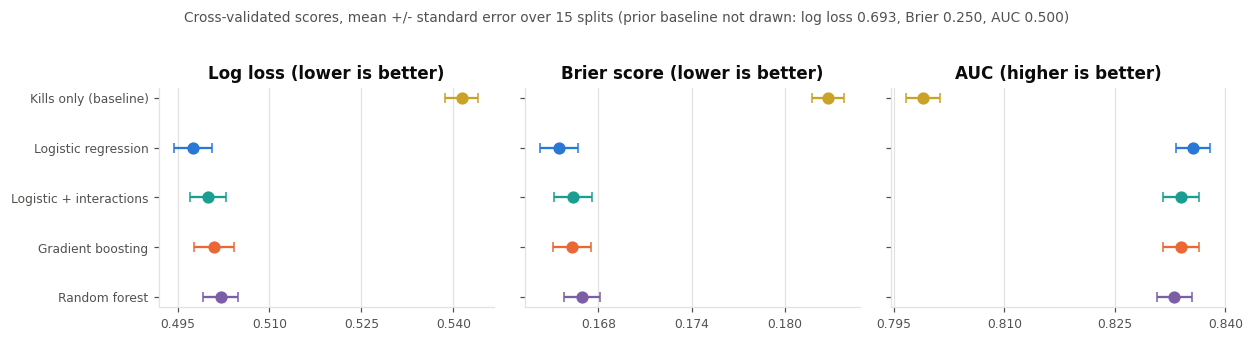

In [6]:
METRICS = ["log_loss", "brier", "auc", "accuracy", "ece"]
agg = cv.groupby("model")[METRICS].agg(["mean", "std"])
table = pd.DataFrame({m: {"log loss": agg.loc[m, ("log_loss", "mean")],
                          "log loss SE": agg.loc[m, ("log_loss", "std")] / np.sqrt(J),
                          "Brier": agg.loc[m, ("brier", "mean")],
                          "AUC": agg.loc[m, ("auc", "mean")],
                          "accuracy": agg.loc[m, ("accuracy", "mean")],
                          "ECE": agg.loc[m, ("ece", "mean")]} for m in MODELS}).T
table.index = [LABEL[m] for m in MODELS]
print(f"Mean over {J} cross-validation splits (SE = standard error of the mean across splits)")
display(table.round(4))

show = [m for m in MODELS if m != "prior"]       # the prior would stretch the axis until the rest look identical
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.0))
for ax, (col, title) in zip(axes, [("log_loss", "Log loss (lower is better)"), ("brier", "Brier score (lower is better)"),
                                   ("auc", "AUC (higher is better)")]):
    for k, m in enumerate(show):
        mean, se = agg.loc[m, (col, "mean")], agg.loc[m, (col, "std")] / np.sqrt(J)
        ax.errorbar(mean, k, xerr=se, fmt="o", color=COLOR[m], ecolor=COLOR[m], markersize=7, capsize=3, elinewidth=1.5)
    ax.set_yticks(range(len(show)), [LABEL[m] if ax is axes[0] else "" for m in show])
    ax.invert_yaxis()
    ax.set_title(title)
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.grid(axis="y", visible=False)
fig.suptitle("Cross-validated scores, mean +/- standard error over 15 splits "
             f"(prior baseline not drawn: log loss {agg.loc['prior', ('log_loss', 'mean')]:.3f}, "
             f"Brier {agg.loc['prior', ('brier', 'mean')]:.3f}, AUC 0.500)", fontsize=9, color=INK2, y=1.02)
plt.tight_layout()
plt.show()

### Are the differences real?
Two views of the same question, both paired (every model scored on the same matches/splits):

* the **paired bootstrap** resamples matches (1,000+ times) and reports a 95% interval for the log-loss
  difference between two models, using repeat-0 out-of-fold predictions;
* the **corrected resampled t-test** (Nadeau & Bengio) uses the 15 per-split differences and inflates the variance to
  account for overlapping training sets.

A negative difference means the first model has the *lower* (better) log loss.

In [7]:
rng = np.random.default_rng(SEED)
BOOT = rng.integers(0, n, (2000, n))
loss = {m: per_match_loss(y, oof[m][0]) for m in MODELS}


def compare(a, b):
    # Log loss of a minus log loss of b: per-split t-test and match-level bootstrap interval.
    da = cv[cv.model == a].sort_values(["repeat", "fold"]).log_loss.to_numpy()
    db = cv[cv.model == b].sort_values(["repeat", "fold"]).log_loss.to_numpy()
    d = da - db
    corr = 1 / J + 1 / (N_FOLDS - 1)                       # 1/J + n_test/n_train
    tstat = d.mean() / np.sqrt(corr * d.var(ddof=1)) if d.var(ddof=1) > 0 else 0.0
    pval = 2 * stats.t.sf(abs(tstat), J - 1)
    boot = (loss[a] - loss[b])[BOOT].mean(1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return {"log-loss difference": d.mean(), "bootstrap 95% CI": f"[{lo:+.4f}, {hi:+.4f}]",
            "splits where first is better": f"{int((d < 0).sum())} of {J}", "corrected t-test p": pval}


pairs = [(m, "prior") for m in ("kills_only",) + tuple(CANDIDATES)] + \
        [(m, "kills_only") for m in CANDIDATES] + [(m, "logreg") for m in CANDIDATES[1:]]
comp = pd.DataFrame([{"first": LABEL[a], "second": LABEL[b], **compare(a, b)} for a, b in pairs])
display(comp.set_index(["first", "second"]).round(4))

,,log-loss difference,bootstrap 95% CI,splits where first is better,corrected t-test p
first,second,,,,
Kills only (baseline),Prior (baseline),-0.1517,"[-0.1631, -0.1406]",15 of 15,0.0000
Logistic regression,Prior (baseline),-0.1955,"[-0.2075, -0.1833]",15 of 15,0.0000
Logistic + interactions,Prior (baseline),-0.1930,"[-0.2042, -0.1807]",15 of 15,0.0000
Gradient boosting,Prior (baseline),-0.1920,"[-0.2038, -0.1794]",15 of 15,0.0000
Random forest,Prior (baseline),-0.1910,"[-0.2022, -0.1793]",15 of 15,0.0000
Logistic regression,Kills only (baseline),-0.0438,"[-0.0509, -0.0369]",15 of 15,0.0000
Logistic + interactions,Kills only (baseline),-0.0414,"[-0.0477, -0.0342]",15 of 15,0.0000
Gradient boosting,Kills only (baseline),-0.0404,"[-0.0468, -0.0327]",15 of 15,0.0000
Random forest,Kills only (baseline),-0.0393,"[-0.0453, -0.0331]",15 of 15,0.0000


## 5. Choosing the model
**Selection rule, fixed before looking at the results:**

1. Rank the candidates by mean cross-validated **log loss**. It is the primary metric because the product's output is a
   percentage.
2. Find the best one, then keep every candidate whose mean log loss is within **one standard error** of the best
   (the standard "one-standard-error rule").
3. From those, choose the **simplest** one (list order in Section 3: logistic, logistic + interactions, gradient
   boosting, random forest).

*Why prefer simple when scores are tied:* a model that is no worse within noise but far easier to explain, to check
for drift after a patch, and to ship (logistic coefficients are a few numbers in `win_model.json`; trees would mean
bundling a machine-learning library into the tray app) is the better engineering choice. The rule only prefers a
complex model if it is **measurably** better.

Caveat: the 15 splits overlap, so their standard error is slightly optimistic; the rule is a guide, and
Section 4's paired tests are the stronger evidence.

In [8]:
cand = cv[cv.model.isin(CANDIDATES)].groupby("model").log_loss.agg(["mean", "std"]).loc[CANDIDATES]
best = cand["mean"].idxmin()
se_best = cand.loc[best, "std"] / np.sqrt(J)
threshold = cand.loc[best, "mean"] + se_best
eligible = [m for m in CANDIDATES if cand.loc[m, "mean"] <= threshold]
SELECTED = eligible[0]

print(f"Best mean log loss: {LABEL[best]} = {cand.loc[best, 'mean']:.4f} (SE {se_best:.4f}); threshold = {threshold:.4f}")
for m in CANDIDATES:
    print(f"  {LABEL[m]:<26} {cand.loc[m, 'mean']:.4f}  {'<- within one SE' if m in eligible else ''}")
print(f"\nSELECTED MODEL: {LABEL[SELECTED]}")

# The hyperparameters inner cross-validation picked most often for each candidate.
def modal_params(name):
    c = Counter(cv[cv.model == name].params)
    return json.loads(c.most_common(1)[0][0]), c.most_common(1)[0][1]

for m in CANDIDATES:
    pr, k = modal_params(m)
    print(f"  {LABEL[m]:<26} most-picked settings ({k} of {J} splits): {pr}")

Best mean log loss: Logistic regression = 0.4975 (SE 0.0030); threshold = 0.5005
  Logistic regression        0.4975  <- within one SE
  Logistic + interactions    0.5000  <- within one SE
  Gradient boosting          0.5010  
  Random forest              0.5020  

SELECTED MODEL: Logistic regression
  Logistic regression        most-picked settings (15 of 15 splits): {'logisticregression__C': 0.1}
  Logistic + interactions    most-picked settings (15 of 15 splits): {'logisticregression__C': 0.01}
  Gradient boosting          most-picked settings (12 of 15 splits): {'learning_rate': 0.03, 'max_depth': 2, 'max_iter': 300}
  Random forest              most-picked settings (14 of 15 splits): {'max_features': 'sqrt', 'min_samples_leaf': 30}


## 6. Calibration and ranking
**Calibration:** matches are cut into 10 equal groups by predicted chance; a model that is trustworthy lies on the
diagonal. **ROC:** how well each model ranks winners above losers. Both use repeat-0 out-of-fold predictions.

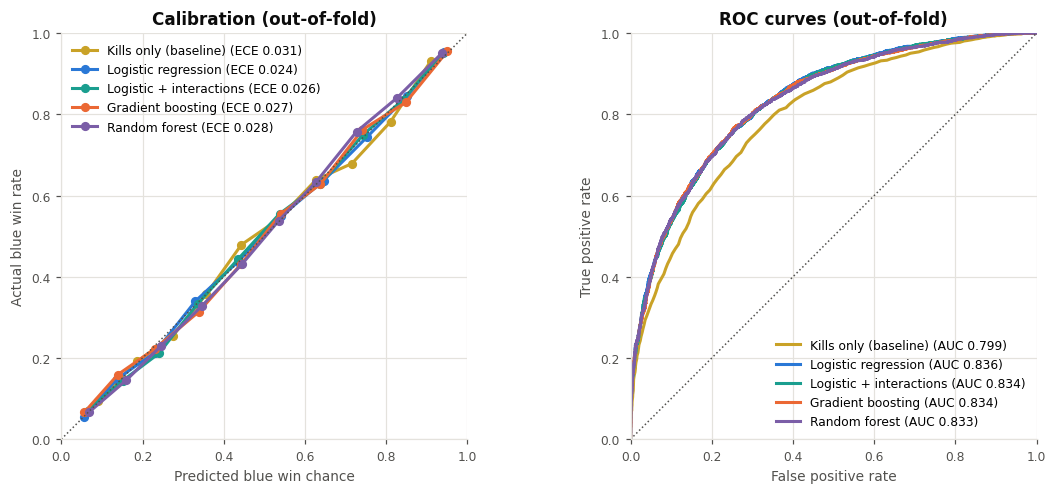

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6))
ax = axes[0]
for m in ["kills_only"] + CANDIDATES:
    p = oof[m][0]
    g = pd.DataFrame({"p": p, "y": y}).groupby(pd.qcut(p, 10, duplicates="drop"), observed=True).mean()
    ax.plot(g.p, g.y, marker="o", markersize=5, color=COLOR[m], label=f"{LABEL[m]} (ECE {table.loc[LABEL[m], 'ECE']:.3f})")
ax.plot([0, 1], [0, 1], color=INK2, linewidth=1, linestyle=":")
ax.set(title="Calibration (out-of-fold)", xlabel="Predicted blue win chance", ylabel="Actual blue win rate",
       xlim=(0, 1), ylim=(0, 1))
ax.set_aspect("equal"); ax.legend(loc="upper left")

ax = axes[1]
for m in ["kills_only"] + CANDIDATES:
    fpr, tpr, _ = roc_curve(y, oof[m][0])
    ax.plot(fpr, tpr, color=COLOR[m], label=f"{LABEL[m]} (AUC {table.loc[LABEL[m], 'AUC']:.3f})")
ax.plot([0, 1], [0, 1], color=INK2, linewidth=1, linestyle=":")
ax.set(title="ROC curves (out-of-fold)", xlabel="False positive rate", ylabel="True positive rate",
       xlim=(0, 1), ylim=(0, 1))
ax.set_aspect("equal"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 7. Error analysis: where does the selected model do well or badly?
Every plot and table here uses the **selected** model's out-of-fold predictions (repeat 0) on the training matches. The
groups are:

* **Rank tier** and **patch**: does it hold up across skill levels and balance changes?
* **Game length** (known only in hindsight, so it can't be used by the model; it shows *which games are hard to call at 15:00*).
* **Kills vs CS agree or conflict**: when the two strongest signals disagree, is the model lost?
* **Towers**, **which side is favoured**, **first blood**.

Small groups give wide intervals, so read the AUC interval (bootstrap, 95%), not only the point.

In [10]:
ea = train.copy()
ea["p"] = oof[SELECTED][0]
ea["game_length"] = pd.cut(ea.game_minutes, [0, 25, 30, 35, 200], right=False,
                           labels=["15-25 min", "25-30 min", "30-35 min", "35+ min"])
sign = np.sign(ea.kills_diff) * np.sign(ea.cs_diff)
ea["kills_vs_cs"] = np.where(sign > 0, "kills and CS agree", np.where(sign < 0, "kills and CS conflict", "one of them is level"))
ea["towers"] = np.select([ea.towers_diff > 0, ea.towers_diff < 0], ["blue ahead", "red ahead"], "even")
ea["favourite"] = np.where(ea.p >= 0.5, "blue favoured", "red favoured")
ea["first_blood"] = np.where(ea.blue_first_blood == 1, "blue got first blood", "red got first blood")

GROUPS = [("Rank tier", "rank_tier", RANKS),
          ("Patch", "patch", sorted(ea.patch.unique())),
          ("Game length (hindsight)", "game_length", ["15-25 min", "25-30 min", "30-35 min", "35+ min"]),
          ("Kills vs CS", "kills_vs_cs", ["kills and CS agree", "kills and CS conflict", "one of them is level"]),
          ("Towers", "towers", ["blue ahead", "even", "red ahead"]),
          ("Favourite", "favourite", ["blue favoured", "red favoured"]),
          ("First blood", "first_blood", ["blue got first blood", "red got first blood"])]


def group_table(df, col, order, n_boot=500, seed=SEED):
    rng = np.random.default_rng(seed)
    out = []
    for g in order:
        sub = df[df[col] == g]
        if len(sub) < 30:
            continue
        yy, pp = sub.blue_win.to_numpy(), sub.p.to_numpy()
        s = score(yy, pp)
        aucs = []
        for _ in range(n_boot):
            i = rng.integers(0, len(sub), len(sub))
            if yy[i].min() != yy[i].max():
                aucs.append(roc_auc_score(yy[i], pp[i]))
        lo, hi = np.percentile(aucs, [2.5, 97.5])
        out.append({"group": g, "n": len(sub), "blue win rate": yy.mean(), "mean predicted": pp.mean(),
                    "accuracy": s["accuracy"], "log loss": s["log_loss"], "AUC": s["auc"], "AUC low": lo, "AUC high": hi})
    return pd.DataFrame(out).set_index("group")


overall = score(y, ea.p.to_numpy())
print(f"Overall ({LABEL[SELECTED]}): log loss {overall['log_loss']:.4f}, AUC {overall['auc']:.4f}, accuracy {overall['accuracy']:.4f}")
group_results = {}
for title, col, order in GROUPS:
    group_results[title] = group_table(ea, col, order)
    print(f"\n{title}")
    display(group_results[title].round(3))

Overall (Logistic regression): log loss 0.4977, AUC 0.8355, accuracy 0.7516



Rank tier


,n,blue win rate,mean predicted,accuracy,log loss,AUC,AUC low,AUC high
group,,,,,,,,
IRON,816,0.449,0.480,0.766,0.469,0.857,0.832,0.881
BRONZE,809,0.486,0.488,0.748,0.503,0.831,0.802,0.857
SILVER,820,0.529,0.495,0.757,0.492,0.844,0.818,0.870
GOLD,816,0.483,0.488,0.751,0.504,0.830,0.802,0.855
PLATINUM,819,0.499,0.495,0.730,0.514,0.824,0.795,0.848
EMERALD,818,0.533,0.528,0.749,0.512,0.822,0.792,0.848
DIAMOND,813,0.481,0.485,0.742,0.512,0.823,0.795,0.852
MASTER_PLUS,816,0.478,0.481,0.770,0.474,0.853,0.823,0.877



Patch


,n,blue win rate,mean predicted,accuracy,log loss,AUC,AUC low,AUC high
group,,,,,,,,
16.18,1249,0.482,0.497,0.754,0.502,0.833,0.808,0.853
16.19,3158,0.501,0.493,0.747,0.495,0.837,0.824,0.850
16.20,2120,0.485,0.488,0.758,0.500,0.835,0.818,0.851



Game length (hindsight)


... (5 outputs left out)


Favourite


,n,blue win rate,mean predicted,accuracy,log loss,AUC,AUC low,AUC high
group,,,,,,,,
blue favoured,3188,0.750,0.753,0.750,0.498,0.725,0.708,0.745
red favoured,3339,0.246,0.243,0.754,0.497,0.724,0.706,0.743



First blood


,n,blue win rate,mean predicted,accuracy,log loss,AUC,AUC low,AUC high
group,,,,,,,,
blue got first blood,3251,0.558,0.558,0.746,0.497,0.831,0.818,0.845
red got first blood,3276,0.427,0.427,0.758,0.498,0.830,0.817,0.843


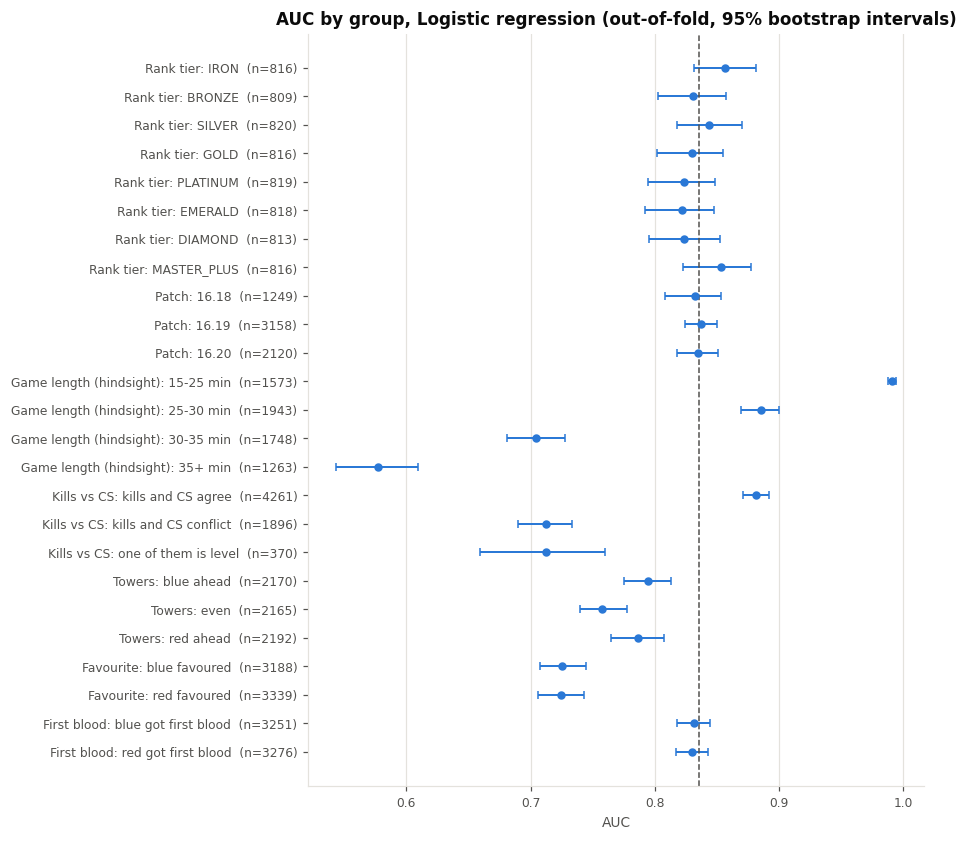

In [11]:
# One forest plot: AUC and its 95% interval for every group (the dashed line is the overall AUC).
labels, mids, los, his, ns = [], [], [], [], []
for title, tbl in group_results.items():
    for g, r in tbl.iterrows():
        labels.append(f"{title}: {g}"); mids.append(r.AUC); los.append(r["AUC low"]); his.append(r["AUC high"]); ns.append(int(r.n))
mids, los, his = map(np.array, (mids, los, his))
fig, ax = plt.subplots(figsize=(8.6, 0.27 * len(labels) + 1))
ypos = np.arange(len(labels))[::-1]
ax.errorbar(mids, ypos, xerr=[mids - los, his - mids], fmt="o", color=BLUE, ecolor=BLUE, capsize=2.5, markersize=4.5, elinewidth=1.3)
ax.axvline(overall["auc"], color=INK2, linewidth=1, linestyle="--")
ax.set_yticks(ypos, [f"{l}  (n={k})" for l, k in zip(labels, ns)])
ax.set(title=f"AUC by group, {LABEL[SELECTED]} (out-of-fold, 95% bootstrap intervals)", xlabel="AUC")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**How to read these groups (three traps):**

* **Game length is a selection effect.** A game that ends by minute 25 was usually already decided at 15:00, so the
  15-25 minute group is easy by construction; 35+ minute games are the ones that turned around or stalled. The gradient
  shows *which games are hard to call*, not that the model behaves differently by length.
* **Towers and favourite-side rows have a squeezed range.** Inside "blue ahead" or "blue favoured" almost every
  prediction is already high, so AUC *within* the group is naturally lower than overall. The log-loss and calibration
  columns (mean predicted vs blue win rate) are the fair comparison there.
* **Conflict is the real weak spot.** When kills and CS disagree, the model has two strong signals pointing opposite
  ways; compare its log loss and AUC with the "agree" row.

### Do the candidates differ in particular conditions?
For each group, each model's log loss minus the **logistic regression's**. Negative (blue) means better than logistic
regression there. If a flexible model only wins in one condition, that tells us what the simple model misses.

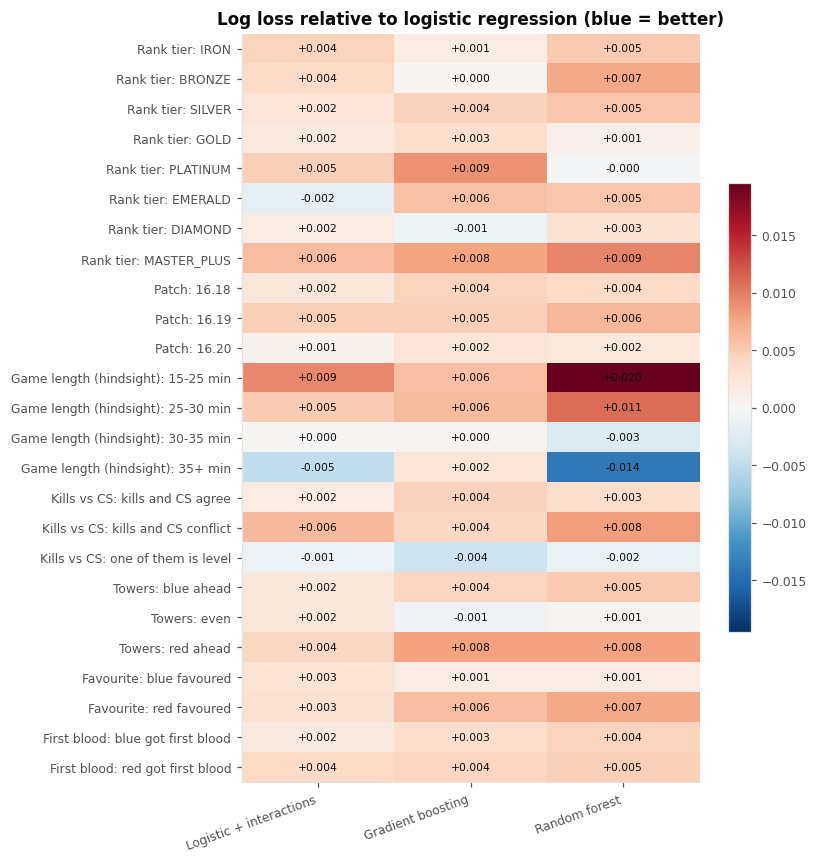

In [12]:
cmp_models = [m for m in CANDIDATES if m != "logreg"]
ea_models = ea.copy()
for m in MODELS:
    ea_models["loss_" + m] = per_match_loss(y, oof[m][0])

rows_, labels_ = [], []
for title, col, order in GROUPS:
    for g in order:
        mask = (ea_models[col] == g).to_numpy()
        if mask.sum() < 30:
            continue
        base = ea_models.loc[mask, "loss_logreg"].mean()
        rows_.append([ea_models.loc[mask, "loss_" + m].mean() - base for m in cmp_models])
        labels_.append(f"{title}: {g}")
delta = pd.DataFrame(rows_, index=labels_, columns=[LABEL[m] for m in cmp_models])

fig, ax = plt.subplots(figsize=(7.6, 0.27 * len(delta) + 1.2))
lim = max(0.01, np.abs(delta.to_numpy()).max())
im = ax.imshow(delta.to_numpy(), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(delta.shape[1]), delta.columns, rotation=20, ha="right")
ax.set_yticks(range(delta.shape[0]), delta.index)
for i in range(delta.shape[0]):
    for j in range(delta.shape[1]):
        ax.text(j, i, f"{delta.iat[i, j]:+.3f}", ha="center", va="center", fontsize=7, color=INK)
ax.grid(False)
ax.set_title("Log loss relative to logistic regression (blue = better)")
plt.colorbar(im, ax=ax, shrink=0.6)
plt.tight_layout(); plt.show()

### Confidence and the worst misses
**Is the model honest about how sure it is?** Games are banded by the favourite's predicted chance; accuracy in each
band should match it. Then the 12 most confident wrong calls, to see what kind of game fools the model.

,matches,accuracy,mean_confidence,share of matches,share of all errors
confidence,,,,,
"[0.5, 0.6)",1212,0.540,0.550,0.186,0.344
"[0.6, 0.7)",1290,0.637,0.650,0.198,0.289
"[0.7, 0.8)",1253,0.760,0.751,0.192,0.186
"[0.8, 0.9)",1474,0.845,0.852,0.226,0.141
"[0.9, 1.0)",1298,0.949,0.944,0.199,0.041


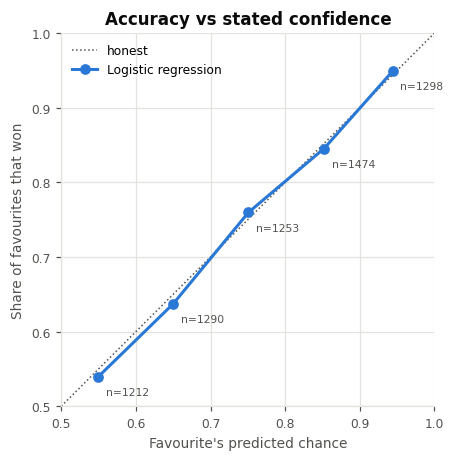

19% of matches are near coin-flips (favourite under 60%); they hold 34% of all errors.


,match_id,rank_tier,patch,game_minutes,p,blue_win,level_sum_diff,cs_diff,kills_diff,assists_diff,towers_diff,dragons_diff,voidgrubs_diff,blue_first_blood
0,NA1_5652619169,MASTER_PLUS,16.19,28.62,0.97,0,6,97,10,13,3,2,3,0
1,NA1_5656629017,IRON,16.20,37.88,0.97,0,9,169,12,2,2,-1,3,1
2,NA1_5660237490,PLATINUM,16.20,28.80,0.03,1,-5,-154,-11,-12,-2,-1,3,0
3,NA1_5647099804,SILVER,16.18,27.83,0.96,0,6,66,18,16,1,1,3,1
4,NA1_5645634082,PLATINUM,16.18,42.48,0.04,1,-8,-123,-9,-4,-2,-1,3,0
5,NA1_5656667275,PLATINUM,16.20,31.58,0.96,0,5,127,6,-1,3,2,3,1
6,NA1_5657888846,SILVER,16.20,33.27,0.95,0,5,85,8,8,2,2,3,0
7,NA1_5657689930,EMERALD,16.20,35.30,0.05,1,-5,-124,-12,-8,0,-2,3,0
8,NA1_5653640818,PLATINUM,16.19,32.95,0.05,1,-6,-40,-15,-15,-1,-2,3,1
9,NA1_5656586480,DIAMOND,16.20,36.38,0.05,1,-4,-40,-13,-10,-2,-2,-3,1


The 12 worst misses were all called at 95%+ confidence and lasted a median of 33 minutes (all games: 29). 12 of the 12 ran past 27 minutes: a lead at 15:00 that was thrown away.


In [13]:
ea["confidence"] = np.maximum(ea.p, 1 - ea.p)
ea["correct"] = (ea.p > 0.5) == (ea.blue_win == 1)
bands = pd.cut(ea.confidence, [0.5, 0.6, 0.7, 0.8, 0.9, 1.0], right=False, include_lowest=True)
conf = ea.groupby(bands, observed=True).agg(matches=("correct", "size"), accuracy=("correct", "mean"), mean_confidence=("confidence", "mean"))
conf["share of matches"] = conf.matches / n
conf["share of all errors"] = ea[~ea.correct].groupby(bands[~ea.correct], observed=True).size() / (~ea.correct).sum()
display(conf.round(3))

fig, ax = plt.subplots(figsize=(4.8, 4.3))
ax.plot([0.5, 1], [0.5, 1], color=INK2, linewidth=1, linestyle=":", label="honest")
ax.plot(conf.mean_confidence, conf.accuracy, marker="o", color=BLUE, label=LABEL[SELECTED])
for x_, y_, k in zip(conf.mean_confidence, conf.accuracy, conf.matches):
    ax.annotate(f"n={k}", (x_, y_), textcoords="offset points", xytext=(5, -12), fontsize=7, color=INK2)
ax.set(title="Accuracy vs stated confidence", xlabel="Favourite's predicted chance", ylabel="Share of favourites that won",
       xlim=(0.5, 1), ylim=(0.5, 1))
ax.set_aspect("equal"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

near_coin = ea.confidence < 0.6
print(f"{near_coin.mean():.0%} of matches are near coin-flips (favourite under 60%); they hold "
      f"{(~ea.correct & near_coin).sum() / (~ea.correct).sum():.0%} of all errors.")
ea["miss_loss"] = per_match_loss(y, ea.p.to_numpy())
worst = ea.sort_values("miss_loss", ascending=False).head(12)
display(worst[["match_id", "rank_tier", "patch", "game_minutes", "p", "blue_win"] + LIVE].round(2).reset_index(drop=True))
print(f"The 12 worst misses were all called at {worst.confidence.min():.0%}+ confidence and lasted a median of "
      f"{worst.game_minutes.median():.0f} minutes (all games: {train.game_minutes.median():.0f}). "
      f"{int((worst.game_minutes >= 27).sum())} of the 12 ran past 27 minutes: a lead at 15:00 that was thrown away.")

## 8. Robustness checks (training data only)
Three questions a reviewer would ask:

1. **Live CS rounding.** The live API reports CS in steps of 10 per player. Train on exact CS, score on the simulated
   live CS (`cs_diff_live_sim`, 0-9 removed per player).
2. **Forward in time.** Fit on patches 16.18 and 16.19, then predict patch 16.20. Random splits mix patches; this
   asks whether the model survives a balance change. (Hyperparameters reused from Section 5.)
3. **Which predictors matter.** Drop each in turn from the logistic model and see how much log loss worsens.

In [14]:
# 1. Live CS rounding, with the selected model, over repeat-0's five splits
params_sel, _ = modal_params(SELECTED)
rows_cs = {"exact CS": [], "live-rounded CS": []}
pe, pl = np.empty(n), np.empty(n)
for r, f, tr, va in [s for s in SPLITS if s[0] == 0]:
    est = MODELS[SELECTED]["build"]().set_params(**params_sel).fit(X.iloc[tr], y[tr])
    pe[va] = est.predict_proba(X.iloc[va])[:, 1]
    Xs = X.iloc[va].copy(); Xs["cs_diff"] = train.cs_diff_live_sim.iloc[va].to_numpy()
    pl[va] = est.predict_proba(Xs)[:, 1]
cs_tbl = pd.DataFrame({"exact CS": score(y, pe), "live-rounded CS": score(y, pl)}).T
print(f"1. Live CS rounding ({LABEL[SELECTED]}, trained on exact CS):")
display(cs_tbl.round(4))

# 2. Forward in time: train on the two earlier patches, test on the latest one
early, late = train.patch.isin(["16.18", "16.19"]).to_numpy(), (train.patch == "16.20").to_numpy()
rows_t = {}
for m in MODELS:
    pr_, _ = modal_params(m) if MODELS[m]["grid"] else ({}, 0)
    est = MODELS[m]["build"]().set_params(**pr_).fit(X[early], y[early])
    rows_t[LABEL[m]] = {**score(y[late], est.predict_proba(X[late])[:, 1]),
                        "cv log loss (random splits)": table.loc[LABEL[m], "log loss"]}
print(f"\n2. Train on patches 16.18-16.19 ({early.sum():,} matches), test on 16.20 ({late.sum():,} matches):")
display(pd.DataFrame(rows_t).T.round(4))

1. Live CS rounding (Logistic regression, trained on exact CS):


,log_loss,brier,auc,accuracy,ece
exact CS,0.4977,0.1655,0.8355,0.7516,0.0087
live-rounded CS,0.4984,0.1658,0.8350,0.7529,0.0094



2. Train on patches 16.18-16.19 (4,407 matches), test on 16.20 (2,120 matches):


,log_loss,brier,auc,accuracy,ece,cv log loss (random splits)
Prior (baseline),0.6929,0.2499,0.5000,0.5151,0.0256,0.6930
Kills only (baseline),0.5492,0.1858,0.7927,0.7165,0.0304,0.5414
Logistic regression,0.4994,0.1654,0.8352,0.7561,0.0182,0.4975
Logistic + interactions,0.5000,0.1657,0.8346,0.7575,0.0128,0.5000
Gradient boosting,0.5016,0.1658,0.8346,0.7632,0.0282,0.5010
Random forest,0.5001,0.1656,0.8352,0.7580,0.0229,0.5020


3. Log loss increase when one predictor is removed (bigger = more useful):


,log loss increase when dropped,splits where it got worse
dragons_diff,0.0087,15 of 15
cs_diff,0.0060,15 of 15
level_sum_diff,0.0029,14 of 15
kills_diff,0.0022,12 of 15
towers_diff,0.0022,13 of 15
voidgrubs_diff,0.0007,11 of 15
assists_diff,0.0006,10 of 15
blue_first_blood,-0.0000,8 of 15


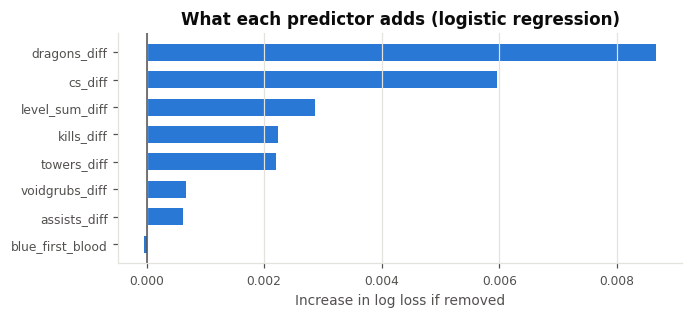

In [15]:
# 3. Drop-one-predictor ablation, logistic regression, the same 15 splits
params_lr, _ = modal_params("logreg")
full_ll = cv[cv.model == "logreg"].sort_values(["repeat", "fold"]).log_loss.to_numpy()
abl = {}
for feat in LIVE:
    keep = [c for c in LIVE if c != feat]
    ll = []
    for r, f, tr, va in SPLITS:
        est = MODELS["logreg"]["build"]().set_params(**params_lr).fit(X.iloc[tr][keep], y[tr])
        ll.append(score(y[va], est.predict_proba(X.iloc[va][keep])[:, 1])["log_loss"])
    d = np.array(ll) - full_ll
    abl[feat] = {"log loss increase when dropped": d.mean(), "splits where it got worse": f"{int((d > 0).sum())} of {J}"}
abl = pd.DataFrame(abl).T
abl["log loss increase when dropped"] = abl["log loss increase when dropped"].astype(float)
abl = abl.sort_values("log loss increase when dropped", ascending=False)
print("3. Log loss increase when one predictor is removed (bigger = more useful):")
display(abl.round(4))

fig, ax = plt.subplots(figsize=(6.4, 3.0))
a2 = abl["log loss increase when dropped"]
ax.barh(a2.index[::-1], a2.values[::-1], color=BLUE, height=0.62)
ax.axvline(0, color=INK2, linewidth=1)
ax.set(title="What each predictor adds (logistic regression)", xlabel="Increase in log loss if removed")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 9. Does the deployed model match what is selected here?
`win_model.json` holds the logistic regression the overlay actually runs. It was trained on **all 8,167** matches, which
includes the matches now reserved as the holdout, so it can't be fairly scored on them. Below, the logistic model is
retrained on the training split only and its coefficients (on standardised inputs) are compared with the deployed ones. Large
differences would mean the deployed model has drifted from this analysis.

In [16]:
deployed = [m for m in json.load(open(ROOT / "win_model.json"))["models"] if m["minute"] == 15][0]
print("Deployed 15-minute model was trained on:", deployed.get("trained_on"))
print("Deployed model's own cross-validated metrics:", deployed.get("cv_metrics"))

lr, _ = fit_model("logreg", X, y, inner_seed=SEED)
scaler, clf = lr.named_steps["standardscaler"], lr.named_steps["logisticregression"]
retrained = pd.Series(clf.coef_[0], index=LIVE)
dep = pd.Series(dict(zip(deployed["features"], deployed["coef"])))
coef_tbl = pd.DataFrame({"deployed (all 8,167 matches)": dep.reindex(LIVE), "retrained (training split only)": retrained})
coef_tbl.loc["intercept"] = [deployed["intercept"], clf.intercept_[0]]
display(coef_tbl.round(3))
print("Predictors the deployed model has that this analysis dropped (constant at 15:00):",
      [f for f in deployed["features"] if f not in LIVE])

Deployed 15-minute model was trained on: 8167 matches from lol_15min_all.csv (matches present in both files)
Deployed model's own cross-validated metrics: {'AUC': 0.837, 'log_loss': 0.4961, 'brier': 0.1647, 'accuracy': 0.753}


,"deployed (all 8,167 matches)",retrained (training split only)
level_sum_diff,0.418,0.420
cs_diff,0.440,0.447
kills_diff,0.502,0.455
assists_diff,0.173,0.187
towers_diff,0.250,0.258
dragons_diff,0.357,0.353
voidgrubs_diff,0.118,0.111
blue_first_blood,-0.037,-0.038
intercept,-0.043,-0.038


Predictors the deployed model has that this analysis dropped (constant at 15:00): ['heralds_diff']


## 10. Final test on the reserved holdout (run once)
Only now is the holdout opened. The selected model (`SELECTED`, fixed in Section 5) and the prior baseline are
fit on the **whole training split** (tuning by 5-fold inner cross-validation) and scored once on the 1,632 held-out
matches. Nothing above is revised after this. First, the fingerprint check proves the file is the one that was
reserved before any modelling.

In [17]:
test = pd.read_csv(DATA_DIR / "lol_15min_live_test_HOLDOUT.csv", dtype={"patch": str})
test["rank_tier"] = pd.Categorical(test.rank_tier, categories=RANKS, ordered=True)
got = hashlib.sha256("\n".join(sorted(test.match_id)).encode()).hexdigest()
expected = (DATA_DIR / "lol_15min_test_HOLDOUT.sha256").read_text().strip()
assert got == expected, "the held-out matches are not the ones that were reserved"
assert not set(test.match_id) & set(train.match_id), "a match is in both train and test"
print(f"Fingerprint matches the reserved set; {len(test):,} held-out matches, none in the training split.")

Xt, yt = test[LIVE], test.blue_win.to_numpy()
final = {}
for m in ["prior", SELECTED]:
    est, params = fit_model(m, X, y, inner_folds=5)
    final[m] = (est, params, est.predict_proba(Xt)[:, 1])
    print(f"{LABEL[m]:<26} fitted on the full training split; settings {params or '(none)'}")

pt = final[SELECTED][2]
hold = pd.DataFrame({LABEL[m]: score(yt, final[m][2]) for m in final}).T
boot_rng = np.random.default_rng(SEED)
HB = boot_rng.integers(0, len(yt), (1000, len(yt)))
cis = {k: np.percentile([score(yt[i], pt[i])[k] for i in HB], [2.5, 97.5]) for k in METRICS}
res = pd.DataFrame({"selected on holdout": {k: score(yt, pt)[k] for k in METRICS},
                    "95% bootstrap CI": {k: f"[{cis[k][0]:.4f}, {cis[k][1]:.4f}]" for k in METRICS},
                    "prior on holdout": {k: hold.loc[LABEL['prior'], k] for k in METRICS},
                    "cross-validation estimate": {k: table.loc[LABEL[SELECTED], {"log_loss": "log loss", "brier": "Brier",
                                                  "auc": "AUC", "accuracy": "accuracy", "ece": "ECE"}[k]] for k in METRICS}})
display(res)

d_boot = np.array([per_match_loss(yt[i], pt[i]).mean() - per_match_loss(yt[i], final["prior"][2][i]).mean() for i in HB])
print(f"Log-loss improvement over the prior baseline on the holdout: {-(per_match_loss(yt, pt).mean() - per_match_loss(yt, final['prior'][2]).mean()):.4f} "
      f"(95% CI {-np.percentile(d_boot, 97.5):.4f} to {-np.percentile(d_boot, 2.5):.4f})")

Fingerprint matches the reserved set; 1,632 held-out matches, none in the training split.
Prior (baseline)           fitted on the full training split; settings (none)


Logistic regression        fitted on the full training split; settings {'logisticregression__C': 0.1}


,selected on holdout,95% bootstrap CI,prior on holdout,cross-validation estimate
log_loss,0.489553,"[0.4652, 0.5137]",0.693001,0.497513
brier,0.161661,"[0.1519, 0.1716]",0.249927,0.165476
auc,0.843055,"[0.8237, 0.8617]",0.500000,0.835613
accuracy,0.765319,"[0.7439, 0.7868]",0.508578,0.751595
ece,0.030374,"[0.0226, 0.0540]",0.056373,0.024212


Log-loss improvement over the prior baseline on the holdout: 0.2034 (95% CI 0.1792 to 0.2275)


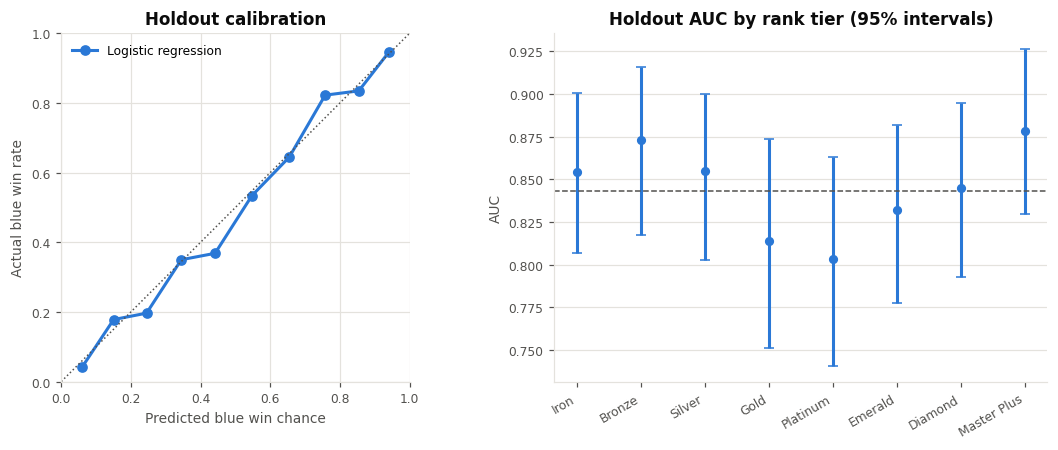

,n,blue win rate,mean predicted,accuracy,log loss,AUC,AUC low,AUC high
group,,,,,,,,
IRON,204,0.446,0.463,0.770,0.473,0.855,0.807,0.900
BRONZE,202,0.485,0.483,0.772,0.449,0.873,0.817,0.916
SILVER,204,0.529,0.518,0.765,0.472,0.855,0.803,0.900
GOLD,204,0.485,0.502,0.745,0.539,0.814,0.751,0.873
PLATINUM,205,0.498,0.513,0.727,0.537,0.804,0.741,0.863
EMERALD,205,0.532,0.489,0.746,0.499,0.832,0.778,0.882
DIAMOND,204,0.480,0.508,0.784,0.489,0.845,0.793,0.895
MASTER_PLUS,204,0.475,0.518,0.814,0.457,0.878,0.830,0.926


In [18]:
# Holdout calibration, and AUC by rank tier (about 200 matches each, so the intervals are wide)
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.2))
ax = axes[0]
g = pd.DataFrame({"p": pt, "y": yt}).groupby(pd.qcut(pt, 10, duplicates="drop"), observed=True).mean()
ax.plot(g.p, g.y, marker="o", color=COLOR[SELECTED], label=LABEL[SELECTED])
ax.plot([0, 1], [0, 1], color=INK2, linewidth=1, linestyle=":")
ax.set(title="Holdout calibration", xlabel="Predicted blue win chance", ylabel="Actual blue win rate", xlim=(0, 1), ylim=(0, 1))
ax.set_aspect("equal"); ax.legend(loc="upper left")

ht = test.copy(); ht["p"] = pt
rank_hold = group_table(ht, "rank_tier", RANKS)
ax = axes[1]
xs = np.arange(len(rank_hold))
ax.errorbar(xs, rank_hold.AUC, yerr=[rank_hold.AUC - rank_hold["AUC low"], rank_hold["AUC high"] - rank_hold.AUC],
            fmt="o", color=BLUE, capsize=3, markersize=5)
ax.axhline(score(yt, pt)["auc"], color=INK2, linewidth=1, linestyle="--")
ax.set_xticks(xs, [r.replace("_", " ").title() for r in rank_hold.index], rotation=30, ha="right")
ax.set(title="Holdout AUC by rank tier (95% intervals)", ylabel="AUC")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
display(rank_hold.round(3))

## 11. Everything in one place, for the modeling note
The cell below prints the numbers a write-up needs, computed from the results above (so they update if the
notebook is re-run), followed by the limitations to state. Section references say where each came from.

In [19]:
sel, pri, ko = LABEL[SELECTED], "Prior (baseline)", "Kills only (baseline)"
g_ = lambda lab, c: table.loc[lab, c]
print("DATA")
print(f"  {n:,} training matches (cross-validation and all error analysis), {len(test):,} held-out matches (scored once).")
print(f"  Blue won {y.mean():.1%} of training matches; patches {', '.join(sorted(train.patch.unique()))}; 8 rank tiers sampled about equally.")
print(f"  Predictors (all live-available, blue minus red): {', '.join(LIVE)}.")
print("\nVALIDATION  (Sections 2 and 4)")
print(f"  Repeated stratified 5-fold x 3 = {J} splits, identical for every model; hyperparameters tuned by nested 3-fold on log loss.")
print("\nCOMPARISON  (Section 4; mean over splits, +/- SE for log loss)")
for m in MODELS:
    L = LABEL[m]
    print(f"  {L:<26} log loss {g_(L, 'log loss'):.4f} +/- {g_(L, 'log loss SE'):.4f}   Brier {g_(L, 'Brier'):.4f}   AUC {g_(L, 'AUC'):.4f}   acc {g_(L, 'accuracy'):.3f}   ECE {g_(L, 'ECE'):.3f}")
print(f"\nSELECTED: {sel}  (rule: simplest candidate within one SE of the best log loss; best was {LABEL[best]})")
print(f"  vs prior baseline: log loss {g_(sel, 'log loss') - g_(pri, 'log loss'):+.4f}, AUC {g_(sel, 'AUC') - g_(pri, 'AUC'):+.4f}")
print(f"  vs kills-only baseline: log loss {g_(sel, 'log loss') - g_(ko, 'log loss'):+.4f}, AUC {g_(sel, 'AUC') - g_(ko, 'AUC'):+.4f}")
print("\nHOLDOUT  (Section 10, scored once)")
print(f"  {sel}: log loss {res.loc['log_loss', 'selected on holdout']:.4f}, AUC {res.loc['auc', 'selected on holdout']:.4f}, "
      f"accuracy {res.loc['accuracy', 'selected on holdout']:.3f}, ECE {res.loc['ece', 'selected on holdout']:.3f}")
print(f"  prior baseline: log loss {res.loc['log_loss', 'prior on holdout']:.4f}")
print(f"  Holdout AUC {res.loc['auc', 'selected on holdout']:.3f} vs cross-validation {res.loc['auc', 'cross-validation estimate']:.3f}; "
      f"the holdout's 95% interval is {res.loc['auc', '95% bootstrap CI']}.")
gaps_ = {LABEL[m]: cand.loc[m, "mean"] - cand.loc["logreg", "mean"] for m in CANDIDATES if m != "logreg"}
acc_c = table.loc[[LABEL[m] for m in CANDIDATES], "accuracy"]
print("\nWHY THIS MODEL  (Sections 4-5)")
print("  No flexible model beat it: log loss relative to logistic regression is " + ", ".join(f"{k} {v:+.4f}" for k, v in gaps_.items()) + " (positive = worse).")
ece_c = table.loc[[LABEL[m] for m in CANDIDATES], "ECE"]
print(f"  Calibration error (ECE): {', '.join(f'{k} {v:.3f}' for k, v in ece_c.items())}; accuracy differs by only {acc_c.max() - acc_c.min():.3f} across the four.")
print("  The trees and interaction terms found no extra signal beyond a weighted sum of the eight statistics, so their added flexibility only adds variance. Logistic regression is also the cheapest to explain and to ship (a few coefficients in win_model.json).")
for col in delta.columns:
    g_best, v_best = delta[col].idxmin(), delta[col].min()
    if v_best < 0:
        print(f"  {col}: its best case against logistic regression is '{g_best}' ({v_best:+.3f} log loss); it is better in {(delta[col] < 0).sum()} of {len(delta)} groups and worse in {(delta[col] > 0).sum()}.")
print("\nERROR ANALYSIS  (Section 7; selected model, out-of-fold)")
ranks_ = group_results["Rank tier"]
print(f"  AUC by rank: best {ranks_.AUC.idxmax()} {ranks_.AUC.max():.3f}, worst {ranks_.AUC.idxmin()} {ranks_.AUC.min():.3f}.")
gl_ = group_results["Game length (hindsight)"]
print(f"  AUC by game length: {', '.join(f'{k} {v:.3f}' for k, v in gl_.AUC.items())}.")
kc_ = group_results["Kills vs CS"]
print(f"  Log loss when kills and CS agree vs conflict: {kc_.loc['kills and CS agree', 'log loss']:.3f} vs {kc_.loc['kills and CS conflict', 'log loss']:.3f}.")
print(f"  {near_coin.mean():.0%} of matches are near coin-flips (favourite under 60%) and hold {(~ea.correct & near_coin).sum() / (~ea.correct).sum():.0%} of all errors.")
print(f"  Predictor that matters most (drop-one): {abl.index[0]} (+{abl.iloc[0, 0]:.4f} log loss); least: {abl.index[-1]} ({abl.iloc[-1, 0]:+.4f}).")
print(f"  Live CS rounding changes log loss by {cs_tbl.loc['live-rounded CS', 'log_loss'] - cs_tbl.loc['exact CS', 'log_loss']:+.4f}.")
print("\nLIMITATIONS TO STATE")
for s in [
    "Information ceiling: eight team-level statistics at 15:00 cannot see champion matchups, player skill, or what happens after minute 15; "
    "an AUC well short of 1 is expected, not a modelling failure.",
    "Sampling: matches were drawn about equally from eight rank tiers, so the rank mix is not the natural one, and the data cover three patches "
    "(16.18-16.20, Sep 14 - Oct 16 2026). Win rates and coefficients may shift with the next patch.",
    f"Repeated players: {REPEAT['repeat']:,} of {REPEAT['players']:,} players ({REPEAT['repeat'] / REPEAT['players']:.0%}) appear in more than one training "
    f"match (the most frequent in {REPEAT['max']}). Matches are treated as independent; the models use no player identity, which limits "
    "but does not remove the risk of optimistic estimates.",
    "Live mismatch: the live API rounds CS to steps of 10 per player; this was simulated from team totals (Section 8), not observed in real games.",
    "Hindsight groups: game length is not known at 15:00, so those rows of the error analysis explain errors; they are not usable features.",
    "The deployed win_model.json was trained on all 8,167 matches, including the holdout, so it cannot be scored on the holdout; "
    "the retrained logistic model here uses the training split only (Section 9).",
    "Small subgroups (about 200 matches per rank tier on the holdout) give wide intervals; differences between ranks are mostly within noise.",
    "The model reports association, not cause: a tower lead predicts a win here, it is not shown to cause one.",
]:
    print("  -", s)

DATA
  6,527 training matches (cross-validation and all error analysis), 1,632 held-out matches (scored once).
  Blue won 49.2% of training matches; patches 16.18, 16.19, 16.20; 8 rank tiers sampled about equally.
  Predictors (all live-available, blue minus red): level_sum_diff, cs_diff, kills_diff, assists_diff, towers_diff, dragons_diff, voidgrubs_diff, blue_first_blood.

VALIDATION  (Sections 2 and 4)
  Repeated stratified 5-fold x 3 = 15 splits, identical for every model; hyperparameters tuned by nested 3-fold on log loss.

COMPARISON  (Section 4; mean over splits, +/- SE for log loss)
  Prior (baseline)           log loss 0.6930 +/- 0.0000   Brier 0.2499   AUC 0.5000   acc 0.508   ECE 0.032
  Kills only (baseline)      log loss 0.5414 +/- 0.0027   Brier 0.1828   AUC 0.7990   acc 0.717   ECE 0.031
  Logistic regression        log loss 0.4975 +/- 0.0030   Brier 0.1655   AUC 0.8356   acc 0.752   ECE 0.024
  Logistic + interactions    log loss 0.5000 +/- 0.0030   Brier 0.1663   AUC 0